-Martina Yed- Análisis y Procesamiento de Señales

TS3: Análisis de Fourier: FFT, desparramo, interpolación y ventaneo.

a)

Definimos la frecuencia de muestreo $f_s=1000$, el número de muestras $N=1000$ y la resolución espectral $\Delta f=1HZ$. Utilizamos una amplitud $A = \sqrt{2}$ para asegurar que la potencia normalizada (varianza) de la senoidal sea unitaria. Luego, calculamos la DFT para las tres frecuencias. Cuando la frecuencia de la senoidal es un múltiplo entero de la resolución $\Delta f$, la energía se concentra perfectamente. Si hay un desfase fraccionario, la ventana temporal finita provoca que la energía se filtre hacia otros bines.

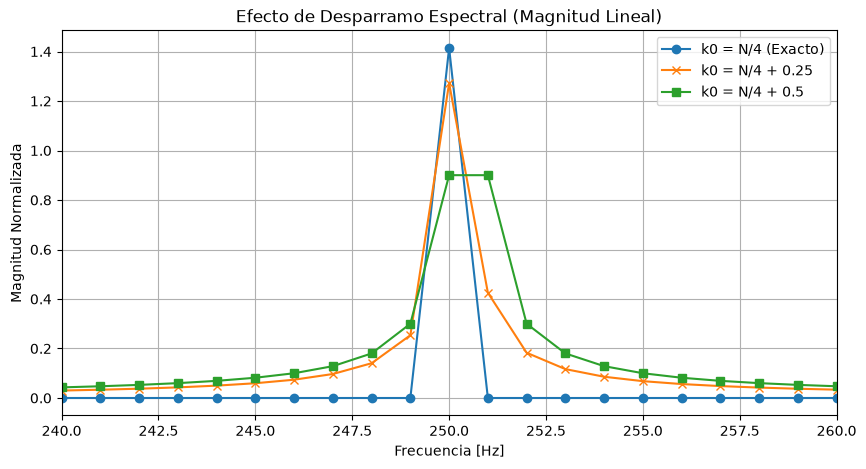

In [1]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000
N = 1000
df = fs / N
A = np.sqrt(2) 

tt = np.arange(N) / fs
f = np.arange(N // 2) * df

f0_1 = (N / 4) * df           # Exacto en el bin
f0_2 = ((N / 4) + 0.25) * df  # Desfase de +0.25 bin
f0_3 = ((N / 4) + 0.5) * df   # Desfase de +0.5 bin 

# Generación directa de señales y cálculo de la DFT
X1 = np.fft.fft(A * np.sin(2 * np.pi * f0_1 * tt))
X2 = np.fft.fft(A * np.sin(2 * np.pi * f0_2 * tt))
X3 = np.fft.fft(A * np.sin(2 * np.pi * f0_3 * tt))

# Magnitud normalizada 
mag_X1 = np.abs(X1[:N // 2]) / (N // 2)
mag_X2 = np.abs(X2[:N // 2]) / (N // 2)
mag_X3 = np.abs(X3[:N // 2]) / (N // 2)

plt.figure(figsize=(10, 5))
plt.plot(f, mag_X1, label='k0 = N/4 (Exacto)', marker='o', linestyle='-')
plt.plot(f, mag_X2, label='k0 = N/4 + 0.25', marker='x', linestyle='-')
plt.plot(f, mag_X3, label='k0 = N/4 + 0.5', marker='s', linestyle='-')

plt.title('Efecto de Desparramo Espectral (Magnitud Lineal)')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Magnitud Normalizada')
plt.xlim(240, 260) 
plt.grid(True)
plt.legend()
plt.show()

Este gráfico lineal nos permite observar la dispersión de la energía de forma directa. Para la desintonía nula *X1* ($k_0 = 250$), vemos un único impulso ideal. A medida que introducimos el desfase fraccionario de *X2* $+0.25$ y *X3* $+0.5$ bines, la DFT está tomando muestras de la función sinc subyacente en puntos distintos de cero, evidenciando el desparramo (leakage) hacia las frecuencias cercanas.  

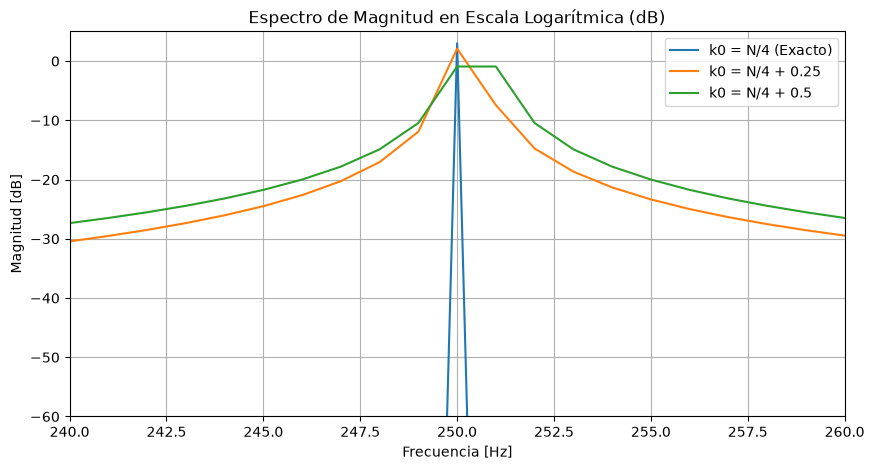

In [2]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000
N = 1000
df = fs / N
A = np.sqrt(2) 

tt = np.arange(N) / fs
f = np.arange(N // 2) * df

f0_1 = (N / 4) * df           
f0_2 = ((N / 4) + 0.25) * df  
f0_3 = ((N / 4) + 0.5) * df  

X1 = np.fft.fft(A * np.sin(2 * np.pi * f0_1 * tt))
X2 = np.fft.fft(A * np.sin(2 * np.pi * f0_2 * tt))
X3 = np.fft.fft(A * np.sin(2 * np.pi * f0_3 * tt))

mag_X1 = np.abs(X1[:N // 2]) / (N // 2)
mag_X2 = np.abs(X2[:N // 2]) / (N // 2)
mag_X3 = np.abs(X3[:N // 2]) / (N // 2)

#%%graficos
epsilon = 1e-12
mag_X1_dB = 20 * np.log10(mag_X1 + epsilon)
mag_X2_dB = 20 * np.log10(mag_X2 + epsilon)
mag_X3_dB = 20 * np.log10(mag_X3 + epsilon)

plt.figure(figsize=(10, 5))
plt.plot(f, mag_X1_dB, label='k0 = N/4 (Exacto)')
plt.plot(f, mag_X2_dB, label='k0 = N/4 + 0.25')
plt.plot(f, mag_X3_dB, label='k0 = N/4 + 0.5')

plt.title('Espectro de Magnitud en Escala Logarítmica (dB)')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Magnitud [dB]')
plt.xlim(240, 260)
plt.ylim(-60, 5)
plt.grid(True)
plt.legend()
plt.show()

La Transformada de Fourier (FFT) asume que el pedacito de señal (tus 1000 muestras) se va a repetir infinitamente, como si copiaramos y pegaramos ese bloque uno detrás de otro.Cuando encaja perfecto (f0_1): La primera señal cae en $N/4$ (exactamente 250 Hz). Esto significa que la onda completa un número entero de ciclos justo cuando se termina el tiempo. Al repetir el bloque, la unión es perfecta y fluida. La FFT nos muestra un pico limpio.( f0_2 y f0_3): Al correr la frecuencia un poco(250.25 Hz y 250.5 Hz), la onda no llega a cerrar su ciclo antes de que se acabe el tiempo de medición. Cuando la FFT asume que esto se repite, se encuentra con un salto entre el final de una onda y el principio de la siguiente. Para representar esto, la matemática de la FFT tiene que inventar un montón de frecuencias altas que no existían. Esa energía que se derrama por todos lados es el desparramo espectral.
En la teoría, al recortar una señal en el tiempo (como nosotros, que tomamos solo 1000 puntos en vez de una señal infinita), el pico de frecuencia deja de ser una línea perfecta y se ensancha, formando lóbulos laterales/secundarios hacia los costados. Esta es la característica forma de la función Sinc. Si le acertamos a la frecuencia exacta, la FFT lee el pico principal y el resto de las muestras caen justo en los cruces donde las colas de esta función valen cero. Por eso el espectro se ve limpio. En cambio, si le erramos a la frecuencia (desintonía), la FFT empieza a evaluar la señal en puntos donde esta curva ya no es nula, captando energía residual y ensuciando los valores vecinos.
Capaz el gráfico lineal (el primero que grafiqué) no muestra tan bien el desparramo de energía, y pareciera que el espectro es más limpio de lo que en verdad es. Al pasarlo a decibeles, se ve mucho mejor cómo las señales desalineadas (f0_2 y f0_3) levantaron un 'piso de ruido' enorme que en escala lineal estaba completamente escondido.

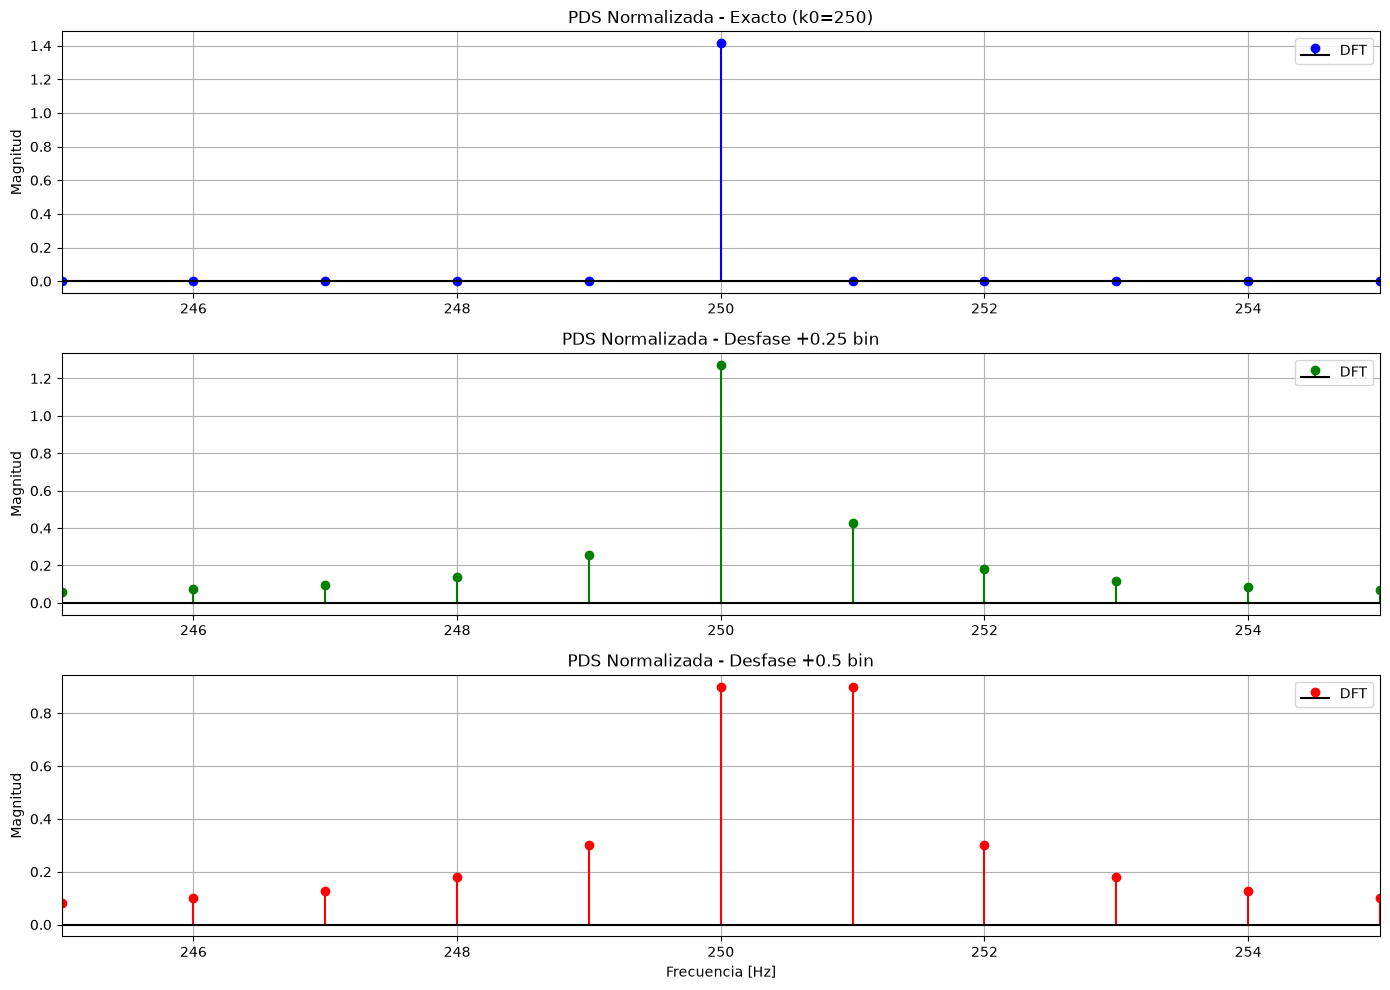

In [4]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000
N = 1000
df = fs / N
A = np.sqrt(2) 

tt = np.arange(N) / fs
f = np.arange(N // 2) * df

f0_1 = (N / 4) * df           
f0_2 = ((N / 4) + 0.25) * df  
f0_3 = ((N / 4) + 0.5) * df    

X1 = np.fft.fft(A * np.sin(2 * np.pi * f0_1 * tt))
X2 = np.fft.fft(A * np.sin(2 * np.pi * f0_2 * tt))
X3 = np.fft.fft(A * np.sin(2 * np.pi * f0_3 * tt))

mag_X1 = np.abs(X1[:N // 2]) / (N // 2)
mag_X2 = np.abs(X2[:N // 2]) / (N // 2)
mag_X3 = np.abs(X3[:N // 2]) / (N // 2)

mags_dft = [mag_X1, mag_X2, mag_X3]
etiquetas = ['Exacto (k0=250)', 'Desfase +0.25 bin', 'Desfase +0.5 bin']
colores = ['b', 'g', 'r']

plt.figure(figsize=(14, 10))
for idx in range(3):
    plt.subplot(3, 1, idx + 1)
    plt.stem(f, mags_dft[idx], linefmt=colores[idx]+'-', markerfmt=colores[idx]+'o', basefmt='k-', label='DFT')
    plt.xlim(245, 255)
    plt.title(f'PDS Normalizada - {etiquetas[idx]}')
    plt.ylabel('Magnitud')
    plt.grid(True)
    plt.legend(loc='upper right')
    if idx == 2:
        plt.xlabel('Frecuencia [Hz]')

plt.tight_layout()
plt.show()

Con este grafico se puede ver mejor y mas comparativamente las 3 señales. 
**El Caso(k0=250):** La frecuencia de la señal coincide perfectamente con un casillero de la FFT. Toda la energía se condensa en un solo bastón, mostrando la magnitud real de la señal sin perder nada hacia los costados.

**Desfase de +0.25 bin:** Al no haber un casillero exacto para la frecuencia real, la energía empieza a migrar. El bastón principal pierde altura (subestimando la magnitud real de la onda) y los casilleros vecinos comienzan a tomar valores distintos de cero.

**Desfase de +0.5 bin:** Es el peor escenario en nuestro tp. La frecuencia cae matemáticamente justo en el medio de dos casilleros. La FFT se ve forzada a repartir la energía casi por igual entre esos dos puntos principales y esparcir el resto hacia los costados. El pico se achata severamente, dando la ilusión de que la señal original era mucho más débil.

El desparramo espectral no elimina la energía de la señal, sino que el algoritmo la redistribuye de forma no ideal por no poder asignarle una frecuencia exacta. Cuanto mayor es el desfase respecto al centro del bin, más se atenúa la lectura de la magnitud principal y más se contamina el entorno. PERO LA ENERGIA SIEMPRE ES LA MISMA.

b)

El Teorema de Parseval establece que la energía total en una secuencia temporal es igual a la energía total de sus componentes frecuenciales. Aplicado a la Transformada Discreta de Fourier (DFT) para calcular la potencia media de una señal discreta de longitud $N$, la relación fundamental se expresa como:  $$P = \frac{1}{N} \sum_{n=0}^{N-1} \vert{}x[n]\vert{}^2 = \frac{1}{N^2} \sum_{k=0}^{N-1} \vert{}X[k]\vert{}^2$$

In [7]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000
N = 1000
df = fs / N
A = np.sqrt(2) 

tt = np.arange(N) / fs
f = np.arange(N // 2) * df

f0_1 = (N / 4) * df           
f0_2 = ((N / 4) + 0.25) * df 
f0_3 = ((N / 4) + 0.5) * df  

x1 = A * np.sin(2 * np.pi * f0_1 * tt)
x2 = A * np.sin(2 * np.pi * f0_2 * tt)
x3 = A * np.sin(2 * np.pi * f0_3 * tt)

X1 = np.fft.fft(x1)
X2 = np.fft.fft(x2)
X3 = np.fft.fft(x3)

mag_X1 = np.abs(X1[:N // 2]) / (N // 2)
mag_X2 = np.abs(X2[:N // 2]) / (N // 2)
mag_X3 = np.abs(X3[:N // 2]) / (N // 2)

Px1_t = np.mean(x1**2)
Px2_t = np.mean(x2**2)
Px3_t = np.mean(x3**2)

Px1_f = np.sum(np.abs(X1)**2) / N**2
Px2_f = np.sum(np.abs(X2)**2) / N**2
Px3_f = np.sum(np.abs(X3)**2) / N**2

print(f"x1 - Potencia en tiempo: {Px1_t:.4f} | Por Parseval: {Px1_f:.4f}")
print(f"x2 - Potencia en tiempo: {Px2_t:.4f} | Por Parseval: {Px2_f:.4f}")
print(f"x3 - Potencia en tiempo: {Px3_t:.4f} | Por Parseval: {Px3_f:.4f}")

x1 - Potencia en tiempo: 1.0000 | Por Parseval: 1.0000
x2 - Potencia en tiempo: 0.9990 | Por Parseval: 0.9990
x3 - Potencia en tiempo: 1.0000 | Por Parseval: 1.0000


Tal como demuestra la identidad de Parseval, la potencia total de la señal se mantiene estrictamente constante (aproximadamente $1.0~W$) en los tres escenarios. La energía matemática es idéntica independientemente de si está concentrada en un único bin o desparramada por todo el espectro. 

Cuando la frecuencia de la senoidal coincide de forma entera con la resolución espectral, la señal completa un número exacto de ciclos dentro de la ventana de adquisición. Al calcular la DFT, las muestras caen exactamente en el pico principal. El resultado es un impulso visualmente perfecto.  Desfase temporal y discontinuidad: Al introducir una desintonía de apenas unos pocos Hertz, la señal se trunca abruptamente antes de lograr cerrar su ciclo completo. Si asumiéramos que esta ventana temporal se repite periódicamente, los extremos de la onda no coincidirían, generando un salto brusco (discontinuidad).Esta discontinuidad en los bordes de la ventana temporal obliga a la DFT a evaluar puntos frecuenciales que ya no caen en los ceros inofensivos de la función matemática. La energía no desaparece, sino que la DFT se ve forzada a "leer" las faldas de la onda, provocando que la potencia se fugue y se distribuya a lo largo de todos los bines adyacentes, alterando drásticamente el gráfico a pesar de ser la misma señal con apenas unos Hertz de diferencia.  
Lo imporante de esto es entender que la potencia total de la señal es idéntica en todos los escenarios; simplemente cambia la forma en que el algoritmo la agrupa o la dispersa a lo largo del espectro.

c)

El zero padding es un truco muy utilizado en análisis espectral para aumentar la resolución aparente en frecuencia de la transformada, al agregar ceros al final de la secuencia en el dominio del tiempo. Este procedimiento muestrea la transformada de Fourier de tiempo discreto (DTFT) de forma más fina, con saltos múltiplos de $2\pi/10N$ en lugar de $2\pi/N$.  


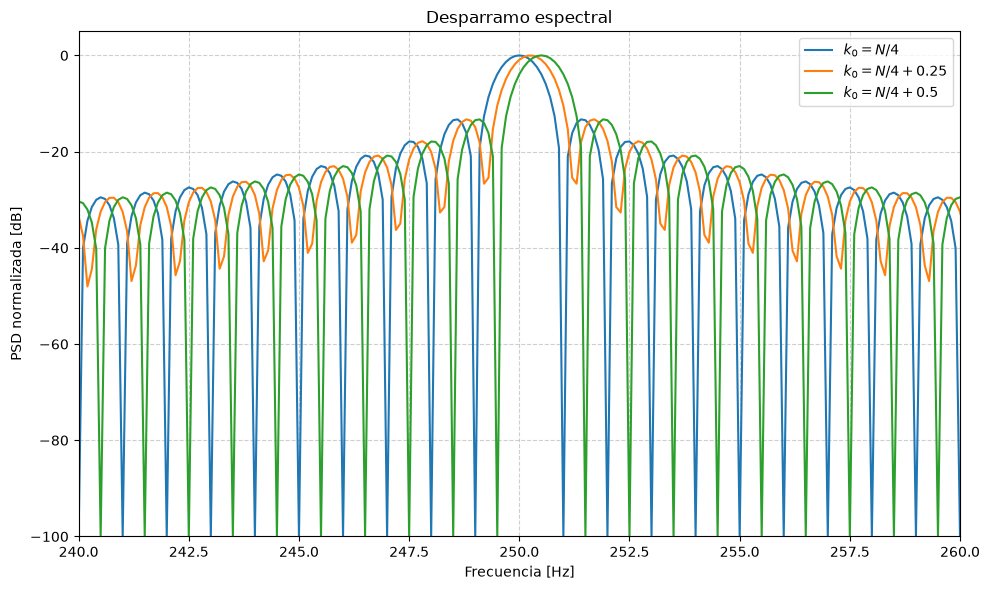

In [9]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000
N = 1000
df = fs / N
A = np.sqrt(2) 

tt = np.arange(N) / fs

f0_1 = (N / 4) * df
f0_2 = ((N / 4) + 0.25) * df
f0_3 = ((N / 4) + 0.5) * df

x1 = A * np.sin(2 * np.pi * f0_1 * tt)
x2 = A * np.sin(2 * np.pi * f0_2 * tt)
x3 = A * np.sin(2 * np.pi * f0_3 * tt)

Factor_pad = 10
N_pad = Factor_pad * N
deltaF1 = fs / N_pad
freqs1 = np.arange(N_pad // 2) * deltaF1

zeroPadding1 = np.zeros(N_pad)
zeroPadding2 = np.zeros(N_pad)
zeroPadding3 = np.zeros(N_pad)

zeroPadding1[0:N] = x1 
zeroPadding2[0:N] = x2 
zeroPadding3[0:N] = x3 

fft_zeroPadding1 = np.fft.fft(zeroPadding1)
fft_zeroPadding2 = np.fft.fft(zeroPadding2)
fft_zeroPadding3 = np.fft.fft(zeroPadding3)

mag_X1_pad = np.abs(fft_zeroPadding1[:N_pad // 2]) / (N // 2)
mag_X2_pad = np.abs(fft_zeroPadding2[:N_pad // 2]) / (N // 2)
mag_X3_pad = np.abs(fft_zeroPadding3[:N_pad // 2]) / (N // 2)

pico_ref = np.max(mag_X1_pad)
db_X1 = 20 * np.log10(np.maximum(mag_X1_pad / pico_ref, 1e-5))
db_X2 = 20 * np.log10(np.maximum(mag_X2_pad / pico_ref, 1e-5))
db_X3 = 20 * np.log10(np.maximum(mag_X3_pad / pico_ref, 1e-5))

plt.figure(figsize=(10, 6))

plt.plot(freqs1, db_X1, label=r'$k_0 = N/4$', color='tab:blue', linewidth=1.5)
plt.plot(freqs1, db_X2, label=r'$k_0 = N/4 + 0.25$', color='tab:orange', linewidth=1.5)
plt.plot(freqs1, db_X3, label=r'$k_0 = N/4 + 0.5$', color='tab:green', linewidth=1.5)

plt.xlim(240.0, 260.0)
plt.ylim(-100, 5)
plt.title('Desparramo espectral')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD normalizada [dB]')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

La Transformada de Fourier de Tiempo Discreto (DTFT) es una función continua de la frecuencia, pero la transformada discreta (DFT) solo la evalúa en puntos discretos.  Al rellenar la secuencia temporal con ceros hasta alcanzar un largo de $10N$, obligás a la transformada a muestrear la DTFT en una grilla diez veces más densa, reduciendo el espaciado entre puntos y evaluando múltiplos de $2\pi/10N$. 
Lo MAS IMPORTANTE DE ENTENDER DE ESTO es que rellenar un vector con ceros al final no inventa información nueva sobre tu señal original.
Agregar ceros sirve para que el algoritmo calcule puntos intermedios. Es como hacer un "zoom digital" o un suavizado: te dibuja la curva con más detalle, lo que esta buenisimo para medir exactamente en qué frecuencia cae la punta del pico y qué amplitud tiene o simplemente para ver mas lindo lo que ya teniamos. Al tener más densidad de puntos, esos lóbulos quedan totalmente al descubierto. El zero padding te deja en exposición toda esa energía desparramada que en el análisis normal se esconde cuando caemos en una frecuencia exacta.

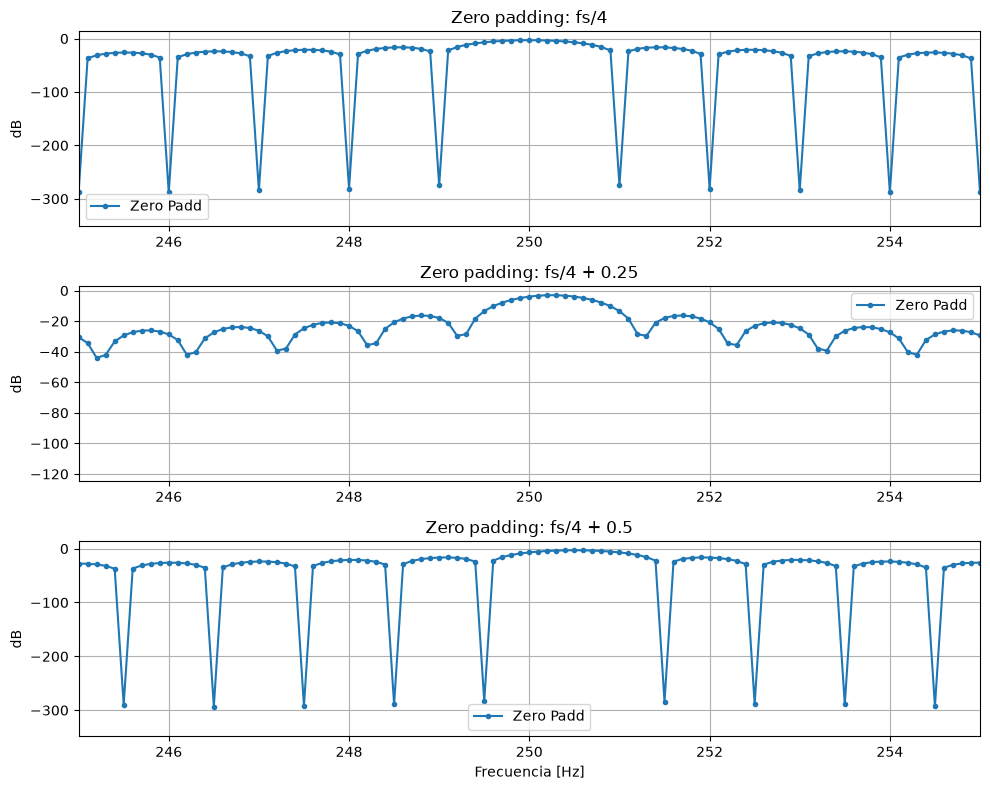

In [8]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000
N = 1000
df = fs / N
A = np.sqrt(2) 

tt = np.arange(N) / fs
f = np.arange(N // 2) * df

f0_1 = (N / 4) * df            # 250 Hz
f0_2 = ((N / 4) + 0.25) * df   # 250.25 Hz
f0_3 = ((N / 4) + 0.5) * df    # 250.5 Hz

x1 = A * np.sin(2 * np.pi * f0_1 * tt)
x2 = A * np.sin(2 * np.pi * f0_2 * tt)
x3 = A * np.sin(2 * np.pi * f0_3 * tt)

X1 = np.fft.fft(x1)
X2 = np.fft.fft(x2)
X3 = np.fft.fft(x3)

mag_X1 = np.abs(X1[:N // 2]) / (N // 2)
mag_X2 = np.abs(X2[:N // 2]) / (N // 2)
mag_X3 = np.abs(X3[:N // 2]) / (N // 2)

##Zero padding
zeroPadding1 = np.zeros(10 * N)
zeroPadding2 = np.zeros(10 * N)
zeroPadding3 = np.zeros(10 * N)

zeroPadding1[0:N] = x1 
zeroPadding2[0:N] = x2 
zeroPadding3[0:N] = x3 

fft_zeroPadding1 = np.fft.fft(zeroPadding1)
fft_zeroPadding2 = np.fft.fft(zeroPadding2)
fft_zeroPadding3 = np.fft.fft(zeroPadding3)

fft_zeroPadding1abs = 1/N * np.abs(fft_zeroPadding1)
fft_zeroPadding2abs = 1/N * np.abs(fft_zeroPadding2)
fft_zeroPadding3abs = 1/N * np.abs(fft_zeroPadding3)

#%%
deltaF1 = fs / (N * 10)
freqs1 = np.arange(10 * N) * deltaF1

plt.figure(figsize=(10, 8))

plt.subplot(3, 1, 1)
plt.plot(freqs1, np.log10(fft_zeroPadding1abs**2)*10, '.-', label='Zero Padd')
plt.title('Zero padding: fs/4')
plt.ylabel('dB')
plt.xlim(245, 255) 
plt.grid(True)
plt.legend()

plt.subplot(3, 1, 2)
plt.plot(freqs1, np.log10(fft_zeroPadding2abs**2)*10, '.-', label='Zero Padd')
plt.title('Zero padding: fs/4 + 0.25')
plt.ylabel('dB')
plt.xlim(245, 255)
plt.grid(True)
plt.legend()

plt.subplot(3, 1, 3)
plt.plot(freqs1, np.log10(fft_zeroPadding3abs**2)*10, '.-', label='Zero Padd')
plt.title('Zero padding: fs/4 + 0.5')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('dB')
plt.xlim(245, 255)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

Este gráfico muestra lo mismo que el aterior, pero con cada señal por separado.Asi sirve para poder visualizar mejor la forma de cada señal.

**conclusión**
El cálculo clásico de la FFT solo evalúa el espectro en ciertos casilleros (los bins), lo que nos oculta la verdadera forma de la señal. Como cortamos la onda de golpe al tomar nuestras muestras (ventana temporal rectangular implicita), su forma real en frecuencia pasa a ser la función Sinc. Si la frecuencia de nuestra señal cae "desintonizada" justo entre los puntos que lee la grilla de la FFT, nos encontramos com un problema de submuestreo visual donde el pico principal se ve más bajo de lo que realmente es y la grilla nos esconde toda la energía que se desparramó por los costados.

Rellenar el vector con ceros viene a arreglar justamente esta falta de puntos. Al agrandar el tamaño de la muestra (aumentar N) metiendo ceros al final, obligamos a la FFT a calcular puntos mucho más juntitos. Básicamente, el algoritmo funciona como un interpolador: nos "une los puntos" y dibuja con mucha claridad la curva real de la función Sinc. Al tener este nuevo grafico (entre comillas, porque sigue siendo lo mismo pero con mas clidad por asi decilrlo), salen a la luz todos los lóbulos laterales (desparramo espectral) que la grilla normal nos estaba omitiendo.

Capaz sueno muy repeitiva con esto, pero es una de las conclusiones que mas me llevo de este tp. Agregar ceros no inventa información física nueva ni mejora la capacidad del sistema para distinguir dos frecuencias que están súper pegadas (resolución verdadera). La técnica únicamente aumenta la densidad de puntos calculados. Esto mejora nuestra resolución aparente o "visual", dándonos una curva más suave que nos permite medir con exactitud dónde cae la punta del lóbulo principal y qué altura tiene, pero trabajando siempre con los mismos datos originales.